# Tracer dispersion 2: shear dispersion in the turbulent Couette flow

**37EFM Environmental Fluid Mechanics, TU/e**

The same blob is now released in the turbulent Couette flow of the GOTM exercise: the velocity $u(z)$ is sheared and the diffusivity $D(z)$ is the turbulent diffusivity of the $k$-$\varepsilon$ closure, which vanishes at the walls and peaks in the core. Both come from the last time step of the GOTM run, stored in `data/couette_profiles.npz`.

Chapter 7 of the notes explains what to expect. Differential advection tilts the patch, vertical diffusion exchanges tracer between fast and slow layers, and the result is a longitudinal spreading far faster than $D$ alone gives: Taylor's shear dispersion, with the effective diffusivity

$$K = -\frac{1}{H}\int_{-H}^{0} u'(z)\left[\int_{-H}^{z}\frac{1}{D(z')}\int_{-H}^{z'}u'(z'')\,dz''\,dz'\right]dz ,$$

valid once the patch is long compared with the depth, after the transverse diffusion time $H^2/D$.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from efmtracer import eulerian, lagrangian, profiles, theory
plt.rcParams['figure.dpi'] = 80

## The profiles

depth-averaged u = 0.594 m/s, velocity difference = 0.859 m/s, depth-averaged D = 0.0310 m^2/s


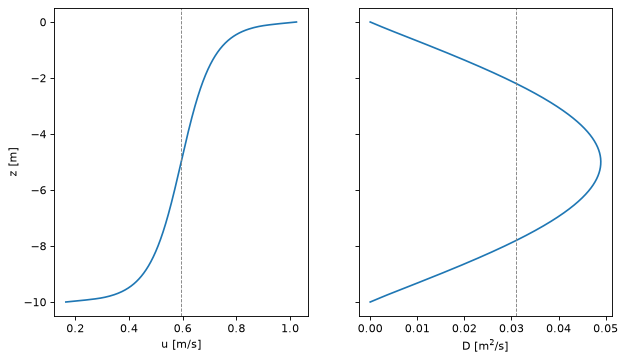

In [2]:
prof = profiles.couette(diffusivity='nuh')      # 'nuh': turbulent diffusivity of a scalar; 'num': eddy viscosity
H = prof.H
zz = np.linspace(-H, 0, 1001)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 5), sharey=True)
ax1.plot(prof.u(zz), zz); ax1.axvline(prof.u_mean, color='gray', ls='--', lw=0.8)
ax1.set_xlabel('u [m/s]'); ax1.set_ylabel('z [m]')
ax2.plot(prof.D(zz), zz); ax2.axvline(prof.D_mean, color='gray', ls='--', lw=0.8)
ax2.set_xlabel('D [m$^2$/s]')
print(f'depth-averaged u = {prof.u_mean:.3f} m/s, velocity difference = {prof.delta_u:.3f} m/s, depth-averaged D = {prof.D_mean:.4f} m^2/s')

## What Taylor predicts

Evaluate the effective diffusivity for these profiles, the order-of-magnitude scaling $(\Delta u)^2 H^2 / D$, and the transverse diffusion time.

In [3]:
K = theory.taylor_K(zz, prof.u(zz), prof.D(zz))
T_mix = theory.mixing_time(H, prof.D_mean)
print(f'Taylor K                  = {K:.2f} m^2/s')
print(f'scaling (du)^2 H^2 / D    = {theory.shear_dispersion_scaling(prof.delta_u, H, prof.D_mean):.0f} m^2/s')
print(f'linear profile, same du   = {theory.taylor_K_linear(prof.delta_u, H, prof.D_mean):.2f} m^2/s')
print(f'K / D                     = {K / prof.D_mean:.0f}')
print(f'transverse diffusion time = {T_mix:.0f} s = {T_mix / 3600:.2f} h')

Taylor K                  = 3.58 m^2/s
scaling (du)^2 H^2 / D    = 2377 m^2/s
linear profile, same du   = 19.81 m^2/s
K / D                     = 115
transverse diffusion time = 3224 s = 0.90 h


## The run

Four hours, in the frame moving with the depth-averaged velocity. The domain must be long enough for the patch after that time: $\sigma_x \approx \sqrt{2Kt}$.

In [4]:
t_end = 4 * 3600
print(f'expected sigma_x after {t_end / 3600:.0f} h: {np.sqrt(2 * K * t_end):.0f} m')
grid = eulerian.Grid(L=4000, nx=800, H=H, nz=100)
c0 = eulerian.gaussian_blob(grid, x0=2000, z0=-H / 2, sigma_x=5.0, sigma_z=0.5)
solver = eulerian.Solver(grid, prof.u, prof.D)        # u_frame defaults to the depth average
times, snaps, hist = solver.run(c0, dt=5.0, t_end=t_end, save_every=1800)
print(f'{len(hist["t"]) - 1} steps, mass {hist["mass"][0]:.4f} -> {hist["mass"][-1]:.4f}')

expected sigma_x after 4 h: 321 m


2880 steps, mass 1.0000 -> 1.0000


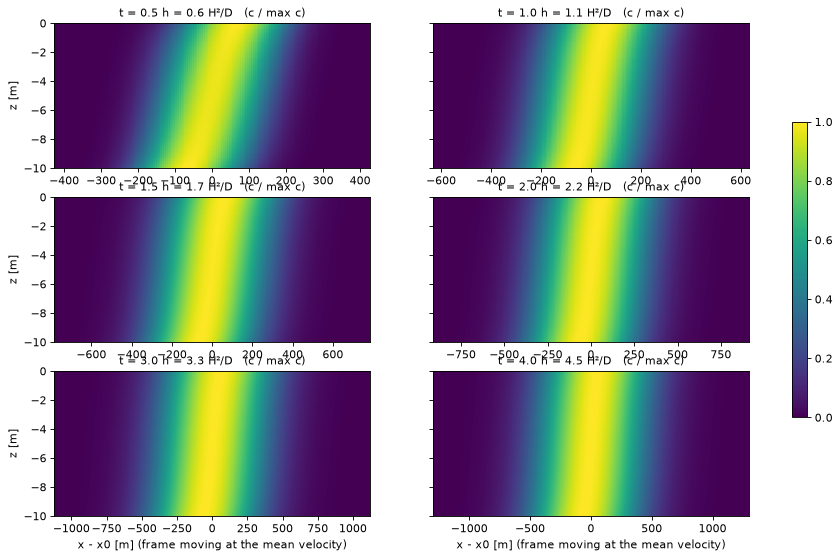

In [5]:
fig, axs = plt.subplots(3, 2, figsize=(14, 8), sharey=True)
for ax, k in zip(axs.ravel(), [1, 2, 3, 4, 6, 8]):
    c = snaps[k]
    pc = ax.pcolormesh(grid.x - 2000, grid.z, c / c.max(), cmap='viridis', vmin=0, vmax=1, shading='nearest')
    cx = c.sum(axis=0) * grid.dz; cm = (cx * grid.x).sum() / cx.sum()
    sx = np.sqrt(((grid.x - cm) ** 2 * cx).sum() / cx.sum())
    ax.set_xlim(cm - 2000 - 4 * sx - 20, cm - 2000 + 4 * sx + 20)
    ax.set_title(f't = {times[k] / 3600:.1f} h = {times[k] / T_mix:.1f} H²/D   (c / max c)', fontsize=10)
for ax in axs[-1]: ax.set_xlabel('x - x0 [m] (frame moving at the mean velocity)')
for ax in axs[:, 0]: ax.set_ylabel('z [m]')
fig.colorbar(pc, ax=axs, shrink=0.6);

Note the changing $x$ scale. Early on the patch is a tilted sheet: the surface tracer runs ahead, the bottom tracer lags. Later it is a long, almost vertical patch: the depth-averaged concentration is what matters, and it spreads like a one-dimensional diffusion problem with $K$ in place of $D$.

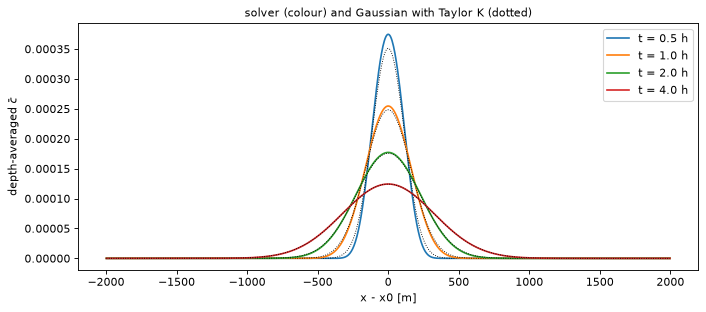

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
for k in [1, 2, 4, 8]:
    cbar = eulerian.depth_average(snaps[k], grid)
    ax.plot(grid.x - 2000, cbar, label=f't = {times[k] / 3600:.1f} h')
    ax.plot(grid.x - 2000, theory.gaussian(grid.x, times[k], K, x0=2000, sigma0=5.0) / H, 'k:', lw=0.8)
ax.set_xlabel('x - x0 [m]'); ax.set_ylabel(r'depth-averaged $\bar c$'); ax.legend()
ax.set_title('solver (colour) and Gaussian with Taylor K (dotted)', fontsize=10);

## Variance against time

Three regimes, and the plot should show them: at first $\sigma_x^2$ grows as $t^2$ (the sheet is stretched by the shear, which is stirring, not mixing), then it bends over, and after about $H^2/D$ it grows linearly as $2Kt$. For comparison, $2Dt$ with the depth-averaged $D$ is what diffusion without shear would give.

K from the late-time slope of sigma_x^2: 3.64 m^2/s   (Taylor: 3.58)


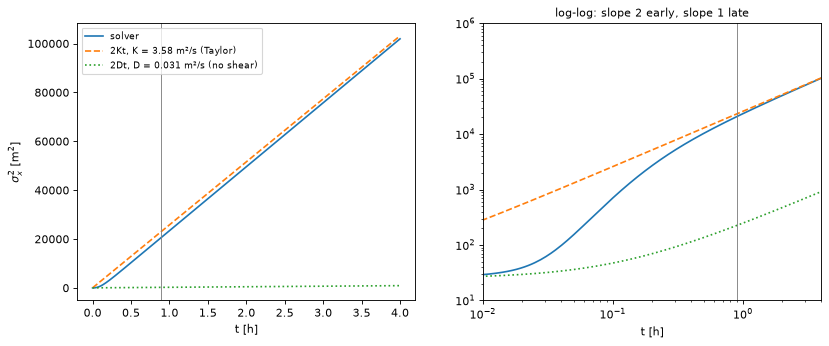

In [7]:
t = hist['t']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for ax in (ax1, ax2):
    ax.plot(t / 3600, hist['var_x'], label='solver')
    ax.plot(t / 3600, 25 + 2 * K * t, '--', label=f'2Kt, K = {K:.2f} m²/s (Taylor)')
    ax.plot(t / 3600, 25 + 2 * prof.D_mean * t, ':', label=f'2Dt, D = {prof.D_mean:.3f} m²/s (no shear)')
    ax.axvline(T_mix / 3600, color='gray', lw=0.8); ax.set_xlabel('t [h]')
ax1.set_ylabel(r'$\sigma_x^2$ [m$^2$]'); ax1.legend(fontsize=8)
ax2.set_xscale('log'); ax2.set_yscale('log'); ax2.set_xlim(1e-2, 4); ax2.set_ylim(10, 1e6)
ax2.set_title('log-log: slope 2 early, slope 1 late', fontsize=10)

# the late-time slope of the variance gives the effective diffusivity directly
late = t > 2 * T_mix
K_fit = np.polyfit(t[late], hist['var_x'][late], 1)[0] / 2
print(f'K from the late-time slope of sigma_x^2: {K_fit:.2f} m^2/s   (Taylor: {K:.2f})')

## Questions

1. By how much does the shear enhance the longitudinal spreading? Compare $K$ with $D$, and with the random-walk estimate $(\Delta u)^2 H^2 / D$ of Section 7.2. Why is the estimate so far off, and in which direction?
2. The effective diffusivity is *inversely* proportional to $D$. Test it: run with `profiles.Profiles` built from the same $u(z)$ but $D$ doubled (`prof.D_table * 2`), and compare the late-time slopes.
3. Which of the two profiles, $u(z)$ or $D(z)$, matters more for $K$? Replace one of them by its depth average and see.
4. The sheet stretched by the shear is reversible, the diffusion is not. Reverse the flow at $t = 0.2\,H^2/D$ (change the sign of `prof.u`) and see whether the sheet reassembles.
5. Exercise 7.1 of the notes gives $K$ for a linear profile in closed form. Check the solver against it with `profiles.linear_shear`.